# 4.0 Analytic Inverse Kinematics and the Wrist Camera

**ELEC3901 Robotic Manipulators, Lab 4** (week 4: Inverse Kinematics and the Wrist Camera)

<br>

Read before this lab: the week 4 lecture and RVC3 Ch. 7.3 (analytic); Ch. 13.1 to 13.2 (the camera). Each section below follows the lecture slides listed next to it.

### Contents

| Section | Where | Time | Lecture slides |
|---|---|---|---|
| [4.1 Existence and multiplicity](#exist) | desk | 10 min | 5-9: Forward vs inverse kinematics; The inverse kinematics problem; Existence: the 2R workspace; Multiplicity: how many solutions?; Two tools: atan2 and the law of cosines |
| [4.2 Two-link analytic IK](#twolink) | desk | 15 min | 10-14: Two-link IK on a 2R arm; Three links for a point: infinitely many; 22: In code: omx_ik |
| [4.3 The full OMX](#full) | desk | 20 min | 15-24: Three-link IK, step by step; The OMX: a base yaw plus the 3R arm; OMX angles: the zero reference; OMX angles: the sign, and the answer; In code: omx_ik; How many OMX solutions?; Checking the answer |
| [4.4 The camera model](#cammodel) | desk | 5 min | 25-31: The wrist camera: a measuring instrument; The pinhole camera, step by step; Lens distortion; Calibrating the camera from the mat |
| [4.5 Placing the camera](#camera) | desk | 20 min | 36-43: Placing the wrist camera, step by step; The image turns with joint 1; Measured vs design mount |
| [4.6 On the arm: your IK, measured by the camera](#arm) | arm | 30 min | 32-35: From marker to base, step by step; 45: Practical: Lab 4 |
| [4.7 The whole lab with the toolbox](#tb) | desk | 5 min | 44: The Robotics Toolbox in practice |

**How this notebook works.** Each section gives the maths from the lecture, a worked case in code, then the next case for you to
write: a *Task* (a function, checked against hidden values) or an *Exercise* (a few lines with `...` blanks, checked against the
toolbox by `try_it`, which prints `OK` or what looks wrong). Each section ends with the same result from `spatialmath`, the way you
will usually do it. *Desk* sections need no arm: do them before the session if you can. Anything marked **(Optional)** is for
when the core is done: skip it if you are short of time. A **Hint** opens when you click it - try without it first.

*Notation.* The pose of the tool frame {E} in the base frame {B} is ${}^{B}\mathbf{T}_{E}$ (Corke), `T_BE` in code. Inverse
kinematics (IK) asks for the joint angles $q$ that give a wanted tool position $\mathbf{p} = (x, y, z)$ and tool pitch $\theta$.
Positive pitch is **nose down**, as on the arm: $\theta = 90°$ points the tool straight down. In the vertical plane of the arm, $r$
is the reach from the joint-1 axis and $z$ the height. Lengths in the text are millimetres; the code works in metres. Equations are
numbered (1), (2), ... through the notebook; the code comments refer to them. The wrist camera's frame is {C}; its mount on the
tool is ${}^{E}\mathbf{T}_{C}$, `T_EC` (Lab 2).

**Checkpoint for sign-off:** The checkpoint line from Section 4.6: omx_ik round trip, accuracy and repeatability over the three targets, omx_ik on the arm (worst tip error by FK of the servo readings), and how far camera_ik placed the camera from where it was asked

Reference versions of previous weeks' tasks are imported from `omx_ref.py`, so last week never blocks this week; the functions you
write here are the ones your assignment will be built from.

> **Safety.** Keep the workspace clear of hands and cables before enabling torque, and set a conservative profile velocity
> (`arm.set_profile(60, 20)` or lower) before commanding motion. If anything unexpected happens, press the power isolator on the
> bench first, then think. Torque off (`arm.torque(False)`) before touching the arm.

The imports for this notebook. Section 4.6 connects to the arm; nothing before it needs the arm or the camera.

In [ ]:
import sys, os
# Repository layout: weekNN/ (notebooks), scripts/ (helper modules), data/ (your measurements, shared by every week).
for _up in ('.', '..', os.path.join('..', '..')):
    if os.path.isdir(os.path.join(_up, 'scripts')):
        _root = os.path.abspath(_up); sys.path.insert(0, os.path.join(_root, 'scripts'))
        os.makedirs(os.path.join(_root, 'data'), exist_ok=True); os.chdir(os.path.join(_root, 'data'))   # files save/load here
        break
import numpy as np, matplotlib.pyplot as plt, time, cv2
import roboticstoolbox as rtb
from spatialmath import SE3, SO3, SE2, UnitQuaternion
from spatialmath.base import trplot, tranimate
from omx_model import omx_robot, omx_ik, Q_LIM, T_EC, P_TIP_E, mount_tilt, look_down_pitch
from omx import OMX
from omx_camera import Camera, tip_in_mat, predicted_T_CM, pose_error
from omx_calib import small_T
from labcheck import check, try_it
NOM = dict(d1=0.0975, l2z=0.11315, l2x=0.0415, l3=0.162, l4=0.123)   # nominal link parameters (m)
from omx_ref import R_to_rpy, chain_T_BM, dh_table, error_stats, fk_dh, inv_T, make_T, mount_from_views, omx_fk, plot_error_field, rot2, rot_about, rotx, roty, rotz, rpy_to_R, se2, step_log, transform_point, transform_points, transl2, trot2   # reference versions of PREVIOUS labs' tasks; your own definitions below override them
np.set_printoptions(precision=4, suppress=True)
%matplotlib inline
omx = omx_robot()              # Robotics Toolbox model (nominal)
T_EC_CAD = T_EC   # the design camera mount (ROBOTIS CAD: optical axis 38 deg below the tool). Each arm's camera sits a little differently: Lab 2
                  # measures yours, and from Lab 3 on the MOUNT cell re-measures it every session and replaces T_EC
HOVER = 0.09      # tip hover height with the tool vertical: the OMX-F reaches r ~ 0.24 m there (touching the mat: r ~ 0.28 m)
CAM_HOVER = 0.15  # tip height for camera measurements, tool pitched with look_down_pitch(T_EC) so the camera looks straight down:
                  # the camera is then ~180 mm up, enough to see the marker ring around the clear zone

In [ ]:
from omx_model import omx_ik as omx_ik_ref        # the module's analytic IK: used only to check your answers (Task 2 replaces omx_ik)
from roboticstoolbox import ET
d1, l2z, l2x, l3, l4 = NOM['d1'], NOM['l2z'], NOM['l2x'], NOM['l3'], NOM['l4']
a2, beta = np.hypot(l2x, l2z), np.arctan2(l2x, l2z)    # equation (1)
Q_HOME = np.radians([0, -60, 60, 30])

<br>

<a id='exist'></a>

### 4.1 Existence and multiplicity (desk)
---

Forward kinematics always has exactly one answer. Inverse kinematics may have none, one, or several. The OMX splits the question.
Joint 1 only turns the vertical plane. In that plane, once the tool pitch is fixed, link 4 is fixed too, and what is left is a
**two-link arm**: the shoulder (joint 2) and the elbow (joint 3). As in Lab 3, link 2 is the straight line from the shoulder axis to
the elbow axis,

$$ a_2 = \sqrt{l_{2x}^2 + l_{2z}^2} = 120.5 \text{ mm}, \qquad \beta = \operatorname{atan2}(l_{2x},\, l_{2z}) \qquad (1) $$

and link 3 is $l_3$ = 162 mm. The two-link arm must put its end, the *wrist point* (joint 4), at a distance $\rho$ from the shoulder.
Fully stretched it reaches $a_2 + l_3$; fully folded, $|a_2 - l_3|$. So a solution exists only inside an annulus:

$$ |a_2 - l_3| \;\le\; \rho = \sqrt{r_w^2 + z_w^2} \;\le\; a_2 + l_3 \qquad (2) $$

Inside it there are two solutions, elbow up and elbow down; on the outer circle one (the arm straight); outside, none. The joint
limits then remove some of these.

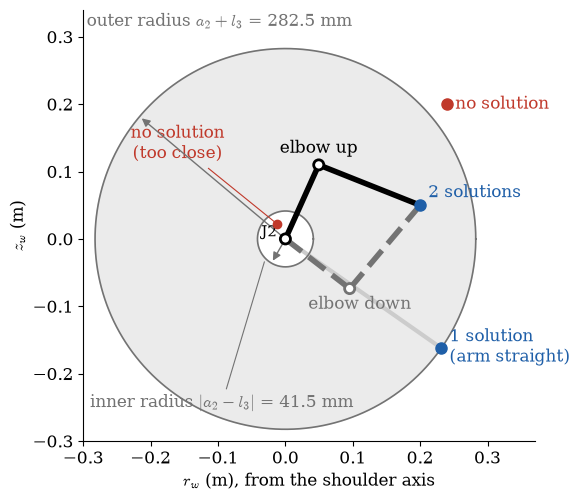

*The shoulder-elbow two-link arm in the vertical plane, origin at the shoulder axis J2. Wrist points in the grey
    annulus, equation (2), have two solutions (elbow up, solid; elbow down, dashed); on the outer circle one; outside it, or inside the
    small inner circle, none. The joint limits are not drawn: they remove more.*

In [ ]:
# --- worked case: the annulus, equation (2), and three wrist points (relative to the shoulder, m) ----------------------
rho_min, rho_max = abs(a2 - l3), a2 + l3
print(f'annulus: {1e3 * rho_min:.1f} mm <= rho <= {1e3 * rho_max:.1f} mm')
for name, (rw, zw) in [('W_a', (0.20, 0.05)), ('W_b', (0.25, 0.20)), ('W_c', (0.02, 0.01))]:
    rho = np.hypot(rw, zw)
    print(f'{name} = ({rw}, {zw}): rho = {1e3 * rho:.1f} mm -> reachable: {rho_min <= rho <= rho_max}')

**Predict, then check.** How many solutions (elbow positions) does each of the three wrist points have, ignoring the joint limits? The
check counts them another way: it walks the elbow round a full circle about the shoulder and counts how often the distance from the
elbow to the wrist point crosses $l_3$.

In [ ]:
# --- Exercise 4.1: how many solutions? ---------------------------------------------------------------------------------
n_solutions = [..., ..., ...]      # for W_a, W_b, W_c: 0, 1 or 2
def _count(rw, zw, n=7200):        # the elbow on a circle of radius a2 about the shoulder: where is it l3 from the wrist point?
    ph = np.linspace(0, 2 * np.pi, n, endpoint=False)
    g = np.hypot(rw - a2 * np.cos(ph), zw - a2 * np.sin(ph)) - l3
    return int(np.count_nonzero(np.sign(g) != np.sign(np.roll(g, 1))))
try_it('solutions for W_a, W_b, W_c', n_solutions, [_count(0.20, 0.05), _count(0.25, 0.20), _count(0.02, 0.01)])

**With the toolbox: what the joint limits leave.** Sample joint vectors inside `Q_LIM`, run `fkine`, and step back $l_4$ along the tool
to the wrist point. The cloud fills only part of the annulus.

In [ ]:
rng = np.random.default_rng(0); qs = rng.uniform(Q_LIM[:, 0], Q_LIM[:, 1], size=(4000, 4)); qs[:, 0] = 0
Ts = omx.fkine(qs)
W = np.array([T.t - l4 * T.R[:, 0] for T in Ts])             # the wrist points (joint 4) in {B}
th = np.linspace(0, 2 * np.pi, 200)
plt.figure(figsize=(5.5, 5)); plt.plot(W[:, 0], W[:, 2] - d1, '.', ms=1, label='wrist points inside Q_LIM')
for rad in (rho_min, rho_max): plt.plot(rad * np.cos(th), rad * np.sin(th), 'k-', lw=0.8)
plt.xlabel('r_w (m)'); plt.ylabel('z_w above the shoulder (m)'); plt.axis('equal'); plt.legend(loc='lower left'); plt.show()

<br>

<a id='twolink'></a>

### 4.2 Two-link analytic IK (desk)
---

The lecture solved a theoretical 2R arm with Lynch & Park's angles $\alpha$, $\beta$, $\gamma$ (slides 10-13); here is the same solve
on the OMX, written with atan2 as in the lecture's code (slide 22). Measure $\phi_2$, the angle of link 2 above the horizontal, and $\phi_3$, the angle of link 3
relative to link 2 (anticlockwise positive). The triangle shoulder-elbow-wrist has sides $a_2$, $l_3$ and $\rho$; the law of cosines
gives the elbow angle:

$$ \cos\phi_3 = c_3 = \frac{r_w^2 + z_w^2 - a_2^2 - l_3^2}{2\,a_2\,l_3} \qquad (3) $$

This is the lecture's law of cosines: $c_3 = \cos(\pi - \beta)$, with $\beta$ the triangle's interior angle at the elbow (on the
slides' 2R arm; elsewhere in this notebook $\beta$ is the L-shaped link's angle, equation (1)). A cosine fixes the angle only up to
its sign, which is the elbow choice. Use `atan2`, never `acos`, so that the quadrant is right:

$$ \phi_3 = \operatorname{atan2}\!\left(s_3,\, c_3\right), \qquad s_3 = \mp\sqrt{1 - c_3^2}
   \quad (-\text{ for elbow up, the OMX's natural posture}) \qquad (4) $$

$|c_3| > 1$ is equation (2) failing: no solution. Then link 2 points at the wrist point, $\gamma = \operatorname{atan2}(z_w, r_w)$,
corrected by the angle the bent arm adds:

$$ \phi_2 = \operatorname{atan2}(z_w,\, r_w) - \operatorname{atan2}\!\left(l_3 s_3,\; a_2 + l_3 c_3\right) \qquad (5) $$

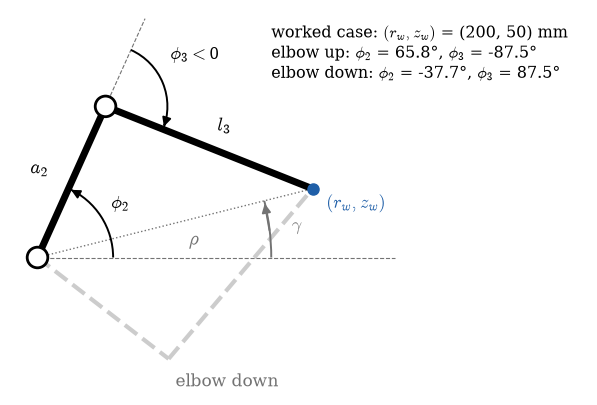

*The two-link solve for the worked wrist point (r_w, z_w) = (200, 50) mm from the shoulder. Elbow up (solid) has
    phi3 < 0; elbow down (dashed) is its mirror image in the line rho from the shoulder to the wrist point.*

In [ ]:
# --- worked case: elbow up for W_a = (0.20, 0.05) m, equations (3)-(5) ------------------------------------------------
rw, zw = 0.20, 0.05
c3 = (rw ** 2 + zw ** 2 - a2 ** 2 - l3 ** 2) / (2 * a2 * l3)              # (3)
s3 = -np.sqrt(1 - c3 ** 2)                                                 # (4) elbow up: s3 < 0
phi3 = np.arctan2(s3, c3)
phi2 = np.arctan2(zw, rw) - np.arctan2(l3 * s3, a2 + l3 * c3)              # (5)
print(f'c3 = {c3:.4f}: phi2 = {np.degrees(phi2):.1f} deg, phi3 = {np.degrees(phi3):.1f} deg   (the figure: 65.8, -87.5)')
fk2 = lambda p2, p3: np.array([a2 * np.cos(p2) + l3 * np.cos(p2 + p3), a2 * np.sin(p2) + l3 * np.sin(p2 + p3)])   # 2-link FK
print('check by forward kinematics:', np.round(fk2(phi2, phi3), 6))

**Your turn: elbow down.** The same wrist point, the other sign in equation (4).

In [ ]:
# --- Exercise 4.2: the elbow-down solution -------------------------------------------------------------------------------
phi3_dn = ...                      # equation (4) with s3 > 0 (rad)
phi2_dn = ...                      # equation (5) (rad)
try_it('2-link FK of your elbow-down solution', lambda: fk2(phi2_dn, phi3_dn), [rw, zw])
try_it('elbow down: phi3 > 0', lambda: phi3_dn > 0, True)

### Task 1 — Planar two-link inverse kinematics
In the vertical plane of the arm the wrist centre is at radius `rw` and height `zw` above joint 2. Write `planar_2r(rw, zw, a2, l3, elbow)`
returning `[phi2, phi3]`: `phi2` = angle of link 2 above the horizontal, `phi3` = angle of link 3 relative to link 2 (anticlockwise
positive). Return `None` if unreachable. For the OMX's normal posture (`elbow='up'`) the relative angle is **negative**.

In [ ]:
def planar_2r(rw, zw, a2, l3, elbow='up'):
    """Planar 2R IK -> [phi2, phi3] (rad) or None if out of reach."""
    # TODO: write your implementation here
    raise NotImplementedError


In [ ]:
# --- self-check (hidden expected values) ---------------------------------------------------------
check('elbow up, rw=0.15 zw=0.10', lambda: planar_2r(0.15, 0.10, 0.1205, 0.162, 'up'), 'fa38cd769d', decimals=5)
check('elbow down, rw=0.15 zw=0.10', lambda: planar_2r(0.15, 0.10, 0.1205, 0.162, 'down'), 'ac750baa31', decimals=5)
check('unreachable returns None', lambda: planar_2r(0.30, 0.10, 0.1205, 0.162) is None, '3eafb06982', decimals=0)

<details><summary><b>Hint</b></summary>

The worked case is the body for `elbow='up'`: equation (3), return `None` if `abs(c3) > 1`, then (4) with the sign chosen by `elbow`,
then (5). Return `np.array([phi2, phi3])`.

</details>

**With the toolbox.** The two-link arm as an ETS in the $x$-$y$ plane ($x$ = $r_w$, $y$ = $z_w$; a positive $\mathbf{R}_z$ is
anticlockwise, like $\phi$). Its forward kinematics must put both of your answers on the wrist point, with the elbow on the side you
asked for. (A numerical solver, `ikine_LM`, finds them too: Lab 5.)

In [ ]:
two = rtb.Robot(ET.Rz() * ET.tx(a2) * ET.Rz() * ET.tx(l3), name='shoulder-elbow')
for elbow in ('up', 'down'):
    try_it(f'planar_2r elbow {elbow}: the 2-link FK lands on the wrist point', lambda: two.fkine(planar_2r(rw, zw, a2, l3, elbow)).t[:2], [rw, zw], tol=1e-9)
    try_it(f'planar_2r elbow {elbow}: phi3 has the sign of the elbow', lambda: np.sign(planar_2r(rw, zw, a2, l3, elbow)[1]), -1 if elbow == 'up' else 1)

<br>

<a id='full'></a>

### 4.3 The full OMX (desk)
---

The full arm, step by step, for a target position $\mathbf{p} = (x, y, z)$ and tool pitch $\theta$. The lecture solved it first as a
planar 3R arm with the OMX's link lengths (slides 15-18; its $\theta_1, \theta_2$ are the $\phi_2, \phi_3$ here), then turned the 3R
angles into servo readings (slides 20-21): that is step 4 below.

*Step 1, the base.* Joint 1 turns the arm's plane onto the target:

$$ q_1 = \operatorname{atan2}(y,\, x), \qquad r = \sqrt{x^2 + y^2} \qquad (6) $$

*Step 2, the wrist point.* Link 4 must point $\theta$ below the horizontal and end at the tip, so the wrist point is $l_4$ back along
it. Measured from the shoulder (which sits $d_1$ up, on the joint-1 axis):

$$ r_w = r - l_4\cos\theta, \qquad z_w = z - d_1 + l_4\sin\theta \qquad (7) $$

*Step 3, the two-link problem* gives $\phi_2, \phi_3$ (equations (3)-(5)).

*Step 4, back to the OMX's joints.* At $q_2 = 0$ link 2 leans $\beta$ forward of vertical, so $\phi_2 = 90° - \beta$ there, and
positive $q$ is nose down (clockwise in the figure). The pitch angles add along the chain, $\theta = q_2 + q_3 + q_4$:

$$ q_2 = (90° - \beta) - \phi_2, \qquad q_3 = (\beta - 90°) - \phi_3, \qquad q_4 = \theta - q_2 - q_3 \qquad (8) $$

Last, reject any $q$ outside the joint limits `Q_LIM`.

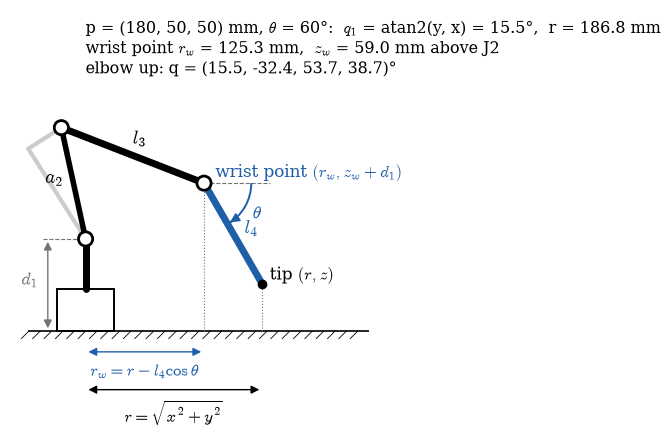

*The worked target p = (180, 50, 50) mm with the tool pitched 60 degrees down, in the arm's plane (turned by q1).
    Stepping back l4 along the tool gives the wrist point; the shoulder-elbow problem then puts joint 4 there.*

In [ ]:
# --- worked case: steps 1 and 2 for the lecture's target, equations (6) and (7) ------------------------------------------
p, theta = np.array([0.18, 0.05, 0.05]), np.radians(60)
q1 = np.arctan2(p[1], p[0]); r = np.hypot(p[0], p[1])                      # (6)
rw5, zw5 = r - l4 * np.cos(theta), p[2] - d1 + l4 * np.sin(theta)           # (7)
print(f'q1 = {np.degrees(q1):.1f} deg, r = {1e3 * r:.1f} mm; wrist point r_w = {1e3 * rw5:.1f} mm, z_w = {1e3 * zw5:.1f} mm above the shoulder')
print('(the figure: 15.5 deg, 186.8 mm; 125.3 mm, 59.0 mm)')

In [ ]:
# --- Exercise 4.3a: steps 3 and 4 ---------------------------------------------------------------------------------------
phi = ...                          # step 3: [phi2, phi3] from your planar_2r, elbow up
q2 = ...                           # step 4, equation (8)
q3 = ...
q4 = ...
q_target = [q1, q2, q3, q4]
try_it('q for the worked target (rad)', q_target, omx_ik_ref(p, theta, 'up'))
try_it('and forward kinematics puts the tip on p', lambda: ... if ... in q_target else omx.fkine(q_target).t, p)

<details><summary><b>Hint</b></summary>

`planar_2r` returns two numbers, so `phi2_, phi3_ = planar_2r(rw5, zw5, a2, l3, 'up')` unpacks them. In (8), $90°$ is `np.pi / 2`.

</details>

### Task 2 — Full inverse kinematics of the OMX
Using `planar_2r`, write `omx_ik(p, pitch, elbow='up', par=NOM)`: joint 1 from the azimuth, wrist centre by backing off `l4` along
the tool direction (`pitch` = tool angle below horizontal, 90 deg = pointing down), joints 2-3 from the planar solution converted to
the OMX zero convention (link 2 vertical + `beta`), joint 4 to make up the pitch. Return `None` if unreachable **or outside `Q_LIM`**; `elbow='any'` tries up then down.
Your function must satisfy `omx_fk(omx_ik(p, pitch))[:3, 3] == p`.

In [ ]:
def omx_ik(p, pitch, elbow='up', par=NOM):
    """Base-frame position p (3,), tool pitch below horizontal (rad) -> q (4,) or None. elbow: 'up', 'down' or 'any'."""
    # TODO: write your implementation here
    raise NotImplementedError


In [ ]:
# --- self-check (hidden expected values) ---------------------------------------------------------
check('q for p=(0.15, 0.05, 0.09) tool down', lambda: omx_ik([0.15, 0.05, 0.09], np.pi / 2), 'd924a84f6c', decimals=5)
check('round trip position', lambda: omx_fk(omx_ik([0.15, 0.05, 0.09], np.pi / 2))[:3, 3], '4221461daa', decimals=5)
check('tilted tool, p=(0.20, -0.03, 0.05), 60 deg', lambda: omx_ik([0.20, -0.03, 0.05], np.radians(60)), '5ba83e8e2a', decimals=5)
check('out of reach returns None', lambda: omx_ik([0.30, 0.0, 0.15], np.pi / 2) is None, '3eafb06982', decimals=0)

<details><summary><b>Hint</b></summary>

Exercise 4.3a is the body for one elbow. Add: `elbow='any'` calls `omx_ik(p, pitch, 'up', par)` and, if that is `None`, the same with
`'down'`; `None` from `planar_2r` passes straight out; and the limit test
`np.all(q >= Q_LIM[:, 0]) and np.all(q <= Q_LIM[:, 1])`. Take the lengths from `par` (`par['l4']`, ...), not the global names.

</details>

**With the toolbox: the round trip.** Random joint vectors inside the limits, forward kinematics, then your IK for both elbows,
against the module's `omx_ik`: the same answers, and the same `None`s.

In [ ]:
def round_trip(n=200, seed=0):
    rng = np.random.default_rng(seed); worst, branch = 0.0, 0
    for _ in range(n):
        q = rng.uniform(Q_LIM[:, 0], Q_LIM[:, 1]); pt = omx.fkine(q).t; pitch = q[1] + q[2] + q[3]
        for e in ('up', 'down'):
            a, b = omx_ik(pt, pitch, e), omx_ik_ref(pt, pitch, e)
            if (a is None) != (b is None): branch += 1
            elif a is not None: worst = max(worst, np.linalg.norm(omx.fkine(a).t - pt))
    return worst, branch
try_it('round trip: worst tip error (m), and how many None mismatches', lambda: round_trip(), [0.0, 0], tol=1e-9)

**Task 2 finishes on the arm.** The round trip above checks your IK against forward kinematics in the model. Section 4.6 starts
with the same test on the real arm: your `omx_ik` moves it, and forward kinematics of the joint angles the servos read back must
put the tip within 5 mm of where you asked.

**Which elbow is home?** Home is $q = (0, -60, 60, 30)°$. Decide from the picture of the arm in your head (or from the sign of $\phi_3$
in equation (8)), then check.

In [ ]:
# --- Exercise 4.3b: is home elbow up? ------------------------------------------------------------------------------------
home_is_elbow_up = ...             # True or False
p_home = omx.fkine(Q_HOME).t
try_it('home is elbow up', home_is_elbow_up, np.allclose(omx_ik_ref(p_home, np.radians(30), 'up'), Q_HOME))

**(Optional) How often is elbow down possible at all?** For when the rest of the section is done: over many random reachable poses,
how often does the elbow-down solution stay inside the joint limits?

In [ ]:
# --- (Optional) Exercise 4.3c: how often is elbow down possible at all? ----------------------------------------------------
rng = np.random.default_rng(2)
Qr = rng.uniform(Q_LIM[:, 0], Q_LIM[:, 1], size=(1000, 4))     # 1000 random joint vectors inside the limits
frac_down = ...                    # the fraction of these poses whose (position, pitch) your omx_ik can ALSO reach elbow down
try_it('fraction with an elbow-down solution', frac_down,
       np.mean([omx_ik_ref(omx.fkine(qq).t, qq[1:].sum(), 'down') is not None for qq in Qr]))

<br>

<a id='cammodel'></a>

### 4.4 The camera model (desk)
---

The wrist camera turns a point $\mathbf{P} = (X, Y, Z)$, given in its own frame {C} (OpenCV's: $z$ along the optical axis, $x$ to
the right, $y$ down), into a pixel $(u, v)$, counted from the top-left corner. Through a pinhole, by similar triangles:

$$ u = f\,\frac{X}{Z} + c_x, \qquad v = f\,\frac{Y}{Z} + c_y \qquad (9) $$

$f$ is the focal length in pixels and $(c_x, c_y)$ the principal point, where the optical axis meets the image. As one matrix, the
camera matrix $\mathbf{K}$ (the intrinsics):

$$ Z\begin{bmatrix} u \\ v \\ 1 \end{bmatrix} = \underbrace{\begin{bmatrix} f & 0 & c_x \\ 0 & f & c_y \\ 0 & 0 & 1 \end{bmatrix}}_{\mathbf{K}}
   \begin{bmatrix} X \\ Y \\ Z \end{bmatrix} \qquad (10) $$

A real lens bends the rays first. With the normalised point $x = X/Z$, $y = Y/Z$ and $r^2 = x^2 + y^2$:

$$ x_d = x\,(1 + k_1 r^2 + k_2 r^4), \quad y_d = y\,(1 + k_1 r^2 + k_2 r^4), \qquad u = f x_d + c_x, \quad v = f y_d + c_y \qquad (11) $$

The camera cell fits $f$, $c_x$, $c_y$, $k_1$ and $k_2$ from the mat at the start of every arm session (lecture 4).

In [ ]:
# --- worked case: the lecture's point through the twin's camera, equation (9) ---------------------------------------------
K_twin = np.array([[950.0, 0, 640], [0, 950.0, 360], [0, 0, 1]])           # f = 950 px, c = (640, 360) at 1280 x 720
P_C = np.array([0.030, -0.020, 0.200])                                     # 30 mm right, 20 mm up, 200 mm ahead (m)
uv = (K_twin @ P_C)[:2] / P_C[2]                                           # (10): K P, then divide by Z
print(f'(u, v) = {np.round(uv, 1)} px   (the slide: 782.5, 265.0)')
from omx_camera import load_mat
mat_meta, corners_M = load_mat(scale=1.0)                                  # every mat marker's four corners in {M} (m), as designed
T_BC_view = SE3(0.17, 0.0, 0.20) * SE3.Rx(np.pi) * SE3.Rz(np.pi / 2)       # the lecture's camera worked case: 200 mm above (170, 0) mm
T_CM_pred = T_BC_view.inv()                                                # the mat taken as the base frame, so C_T_M = inv(B_T_C)
print('marker 12 corners in {M} (mm):', np.round(1e3 * corners_M[12][:, :2]).astype(int).tolist())

In [ ]:
# --- the same model on a whole marker: mat marker 12 seen from the worked view, through the twin's camera and the first arm's lens
import os, omx_camera
_kb = [f for f in ('camera_K_baseline.npz', os.path.join(omx_camera.HERE, 'camera_K_baseline.npz')) if os.path.exists(f)][0]
K_b, dist_b = np.load(_kb)['K'], np.load(_kb)['dist'].ravel()             # the first arm's camera (30 Sep 2026): k1, k2 = dist_b[:2]
_rv = cv2.Rodrigues(T_CM_pred.R)[0]
uv_pin = cv2.projectPoints(corners_M[12], _rv, T_CM_pred.t, K_twin, np.zeros(5))[0].reshape(-1, 2)   # equations (9)-(10)
uv_lens = cv2.projectPoints(corners_M[12], _rv, T_CM_pred.t, K_b, dist_b)[0].reshape(-1, 2)        # equation (11)
print('marker 12 corners, pinhole (px):   ', np.round(uv_pin, 1).tolist())
print('the same through the first lens (px):', np.round(uv_lens, 1).tolist())

That is all the camera model this lab needs: OpenCV does these sums for you (`cv2.projectPoints`), and the camera cell fits
$\mathbf{K}$ and the lens every session. Section 4.6 uses the camera as a measuring instrument for your IK. Lecture 4 (slides
25-35) and the optional Minerva page go deeper.

<br>

<a id='camera'></a>

### 4.5 Placing the camera (desk)
---

The wrist camera is bolted to the tool, so wherever the tool goes the camera follows (Lab 2):
${}^{B}\mathbf{T}_{C} = {}^{B}\mathbf{T}_{E}\;{}^{E}\mathbf{T}_{C}$. To put the *camera* somewhere - above a target, looking down
at the mat - turn this round for the tool pose, then solve the tool's IK as before:

$$ {}^{B}\mathbf{T}_{E} = {}^{B}\mathbf{T}_{C}\;\left({}^{E}\mathbf{T}_{C}\right)^{-1} \qquad (12) $$

The OMX sets only four of a tool pose's six numbers (Section 4.3: the yaw is forced, $q_1 = \operatorname{atan2}(y, x)$, and
the roll is zero), so it cannot take every camera pose either. Which can it? The mount
turns the camera $\alpha$ = 38° down about $\hat{\mathbf{y}}_E$ (`mount_tilt(T_EC)`; the image's $x$ axis is $-\hat{\mathbf{y}}_E$),
and the lens sits in the tool's $x$-$z$ plane, so the lens and the optical axis stay in the arm's vertical plane. A camera pose then
has four free numbers, like the tool: the lens position $(x_C, y_C, z_C)$ and the **view pitch** $v$, the angle of the optical axis
below the horizontal.

In [ ]:
# --- worked case: the camera 200 mm above the mat point (170, 0) mm, looking straight down, by equation (12) --------------
p_C = np.array([0.17, 0.0, 0.20])
T_BC_want = SE3(*p_C) * SE3.Rx(np.pi) * SE3.Rz(np.pi / 2)        # z_C down; x_C = -y_E = -y_B, as the mount makes it at q1 = 0
T_BE_want = T_BC_want * T_EC_CAD.inv()                            # (12), with the design mount
x_E = T_BE_want.R[:, 0]
theta_c = np.arctan2(-x_E[2], np.hypot(x_E[0], x_E[1]))           # the tool pitch: x_E points theta below the horizontal
q_c = omx_ik_ref(T_BE_want.t, theta_c)
print(f'tool point {np.round(1e3 * T_BE_want.t, 1)} mm, tool pitch {np.degrees(theta_c):.1f} deg -> q = {np.round(np.degrees(q_c), 1)} deg')
try_it('the camera lands on the wanted pose', lambda: (omx.fkine(q_c) * T_EC_CAD).A, T_BC_want.A)
print('(the figure: tool point (172.1, 0, 143.4) mm, pitch 52.0 deg; q = (0, -50.5, 36.6, 65.9) deg)')

**Without matrices.** In the arm's plane ($r$ outward, $z$ up) the tool axis is $\hat{\mathbf{x}}_E = (\cos\theta, -\sin\theta)$ and
$\hat{\mathbf{z}}_E = (\sin\theta, \cos\theta)$. The optical axis is the tool axis turned $\alpha$ further down, and the lens is
$(o_x, o_z)$ = (-45.9, 33.2) mm from the tool point in {E} (the translation of ${}^{E}\mathbf{T}_{C}$). So for a lens at
$(r_C, z_C)$ looking $v$ below the horizontal:

$$ \theta = v - \alpha \qquad (13) $$

$$ r = r_C - o_x\cos\theta - o_z\sin\theta, \qquad z = z_C + o_x\sin\theta - o_z\cos\theta, \qquad
   q_1 = \operatorname{atan2}(y_C,\, x_C) \qquad (14) $$

and the tool point $(r\cos q_1,\, r\sin q_1,\, z)$ with pitch $\theta$ goes to `omx_ik`. Equation (13) with $v$ = 90° is the module's
`look_down_pitch(T_EC)`, which Lab 3 used to point the camera at the mat.

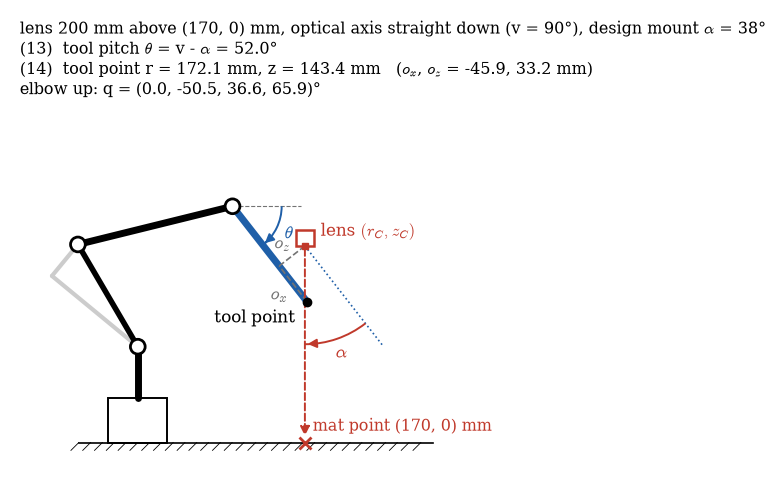

*The worked case in the arm's plane: the lens 200 mm above the mat point (170, 0) mm, the optical axis straight
    down. The tool pitch is 90 - 38 = 52 degrees (13); stepping back from the lens by the mount offset gives the tool point (14), and the
    shoulder-elbow solve of Section 4.3 does the rest.*

In [ ]:
# --- Exercise 4.5a: the worked case by equations (13) and (14) ----------------------------------------------------------
alpha = mount_tilt(T_EC_CAD)       # the mount tilt (38 deg)
o_x = T_EC_CAD.t[0]                # the lens offsets in {E}
o_z = T_EC_CAD.t[2]
theta_6 = ...                      # equation (13) for v = 90 deg (rad)
r_6 = ...                          # equation (14): the tool point's reach (m) ...
z_6 = ...                          # ... and height (m)
try_it('tool pitch (rad)', theta_6, theta_c)
try_it('tool point (r, z) (m)', lambda: [r_6, z_6], [np.hypot(*T_BE_want.t[:2]), T_BE_want.t[2]])

### Task 3 — Placing the camera with IK
Write `camera_ik(p_C, view_pitch, T_EC, elbow='up', par=NOM)`: the joint angles that put the wrist camera's lens at `p_C` (3,) in {B}
with its optical axis `view_pitch` below the horizontal (pi/2 = straight down at the mat), for the camera mount `T_EC` (an `SE3` or a
4 x 4 array). Use equation (13) for the tool pitch (the mount tilt of `T_EC` is `atan2(-T[2, 2], T[0, 2])`), equation (14) for the tool
point (the lens offsets are `T[0, 3]` and `T[2, 3]`, in the tool's x-z plane), then your `omx_ik`. Return `None` where `omx_ik` does, or
if the tool point would be behind the joint-1 axis. Section 4.6 uses it on the arm with your measured mount.

In [ ]:
def camera_ik(p_C, view_pitch, T_EC, elbow='up', par=NOM):
    """Lens position p_C (3,) in {B}, optical axis view_pitch (rad) below horizontal, mount T_EC -> q (4,) or None."""
    # TODO: write your implementation here
    raise NotImplementedError


In [ ]:
# --- self-check (hidden expected values) ---------------------------------------------------------
check('camera 200 mm above (170, 0) mm, looking down', lambda: camera_ik([0.17, 0.0, 0.20], np.pi / 2, T_EC), '1241821fde', decimals=5)
check('the lens lands on p_C', lambda: (omx_fk(camera_ik([0.15, 0.08, 0.20], np.pi / 2, T_EC)) @ T_EC.A)[:3, 3], '3e13e28f2a', decimals=6)
check('looking 60 deg down: the optical axis', lambda: (omx_fk(camera_ik([0.12, -0.06, 0.25], np.radians(60), T_EC)) @ T_EC.A)[:3, 2], '75b90b24b9', decimals=6)
check('out of reach returns None', lambda: camera_ik([0.40, 0.0, 0.30], np.pi / 2, T_EC) is None, '3eafb06982', decimals=0)

<details><summary><b>Hint</b></summary>

If `T_EC` is an `SE3` (it has `.A`), take its matrix, `T = T_EC.A`; otherwise `T = np.array(T_EC)`. The mount tilt is
`np.arctan2(-T[2, 2], T[0, 2])` (the optical axis is the third column), the offsets `T[0, 3]` and `T[2, 3]`. Then Exercise 4.5a with
`view_pitch` for 90 degrees and `q1 = np.arctan2(y, x)`; return `None` if the tool point would be behind the joint-1 axis
(`r <= 0`), else `omx_ik([r * np.cos(q1), r * np.sin(q1), z], pitch, elbow, par)`.

</details>

**With the toolbox.** Forward kinematics times the mount must put the camera exactly on the pose asked for (12). A camera pose further
out than the arm can carry it gives `None`.

In [ ]:
try_it('camera_ik: FK(q) T_EC lands the camera on the pose asked for (12)', lambda: (omx.fkine(camera_ik(p_C, np.pi / 2, T_EC_CAD)) * T_EC_CAD).A, T_BC_want.A, tol=1e-9)
try_it('a camera 300 mm up at x = 400 mm is out of reach', lambda: camera_ik([0.40, 0, 0.30], np.pi / 2, T_EC_CAD) is None, True)
print(f'look_down_pitch(T_EC_CAD) = {np.degrees(look_down_pitch(T_EC_CAD)):.1f} deg = 90 - {np.degrees(mount_tilt(T_EC_CAD)):.0f}: equation (13)')

**What the arm decides for you.** Off the $x$ axis, $q_1 = \operatorname{atan2}(y_C, x_C)$ turns the arm's plane, and the camera turns
with it. Looking straight down, the image's $x$ axis is $-\hat{\mathbf{y}}_E$, so the picture turns about the optical axis. No joint
can undo that (joint 5, the roll, is locked): the fifth and sixth numbers of the camera pose are not yours to choose. The check puts the
arm over (150, 80) mm with the module's IK and measures the angle between the two pictures' $x$ axes.

In [ ]:
# --- Exercise 4.5b: how far is the picture turned? ----------------------------------------------------------------------
turn_deg = ...                     # the image turn (deg) with the camera 200 mm above (150, 80) mm instead of (170, 0) mm
# the check: the same tool point with the arm's plane turned towards (150, 80) mm
q1_b = np.arctan2(0.08, 0.15)
r_b = np.sqrt(T_BE_want.t[0] ** 2 + T_BE_want.t[1] ** 2)
q_b = omx_ik_ref([r_b * np.cos(q1_b), r_b * np.sin(q1_b), T_BE_want.t[2]], theta_c)
x_a = (omx.fkine(q_c) * T_EC_CAD).R[:, 0]        # the image's x axis before ...
x_b = (omx.fkine(q_b) * T_EC_CAD).R[:, 0]        # ... and after
try_it('image turn (deg)', turn_deg, np.degrees(np.arccos(np.clip(x_a @ x_b, -1, 1))), tol=0.01)

<details><summary><b>Hint</b></summary>

(150, 80) mm is 170 mm from the joint-1 axis, like (170, 0) mm: the arm takes the same posture in a plane turned by $q_1$.

</details>

<br>

<a id='arm'></a>

### 4.6 On the arm: your IK, measured by the camera (arm)
---

From here on you need the arm, or the digital twin (`SIMULATE = True` in the next cell). Connect, re-estimate the camera's intrinsics,
and re-measure the camera mount `T_EC` of this arm.

In [ ]:
# --- connect to the arm --------------------------------------------------------------------------------------------
# Safe to re-run: an existing connection is closed first, so the COM port is released before it is opened again.
# SIMULATE = True runs the MuJoCo digital twin (omx_mujoco.py) instead of the real arm: same API, a rendered
# wrist camera, and optional hidden model errors so you can test calibration against ground truth.
SIMULATE = False
PORT = 'auto'                  # finds the OpenRB-150 by its USB id; or set it, e.g. 'COM4' (Device Manager) / '/dev/ttyACM0'
# --- which arm are you on today? Read the asset label on the base. Everything you measure is tagged with it,
#     because zero offsets, camera intrinsics and the camera mount are all properties of THIS arm.
ARM_ID = 'OMX-00'            # EDIT every session
if 'arm' in globals():
    try:
        arm.close()
    except Exception as e:
        print('closing the previous connection:', e)
    del arm
if SIMULATE:
    from omx_mujoco import OMXSim, SimCamera
    arm = OMXSim(view=True)    # view=False if no display; set kin_error=..., joint_offsets=... to hide errors
    # Video: arm.record('run.mp4') writes the wrist camera and a scene camera side by side (same size) while the arm
    # moves; arm.stop_recording() when done.
else:
    arm = OMX(PORT)
print('connected:', 'digital twin' if SIMULATE else arm.port_name, '| arm', ARM_ID)

In [ ]:
# --- wrist camera: manual focus, may have been moved since last week -> re-estimate intrinsics NOW from the mat -------
# AUTO = True: the ARM calibrates the camera itself - it moves through 20 views aimed at the mat and takes a frame at
#   each once the joints and the image are static (omx_autocal.py; about 40 s). Torque goes ON and the arm MOVES:
#   keep hands, cables and objects out of the workspace. A live window shows each view.
# AUTO = False: move the camera over the mat by hand instead (torque off, live window, pause at each view).
# Re-run THIS cell on its own to repeat the calibration: the arm connection above is not touched.
# The gripper is left OPEN for all camera work (closed fingers hide the mat); arm.rest() closes it at the end of the lab.
AUTO = True
CAM_INDEX = 'Innomaker'         # the wrist camera by NAME (a laptop's own webcam is usually camera 0); or a number
if globals().get('cam') is not None:
    try:
        cam.close()                # release the camera held by the previous run
    except Exception:
        pass
cam = None
try:
    if SIMULATE:
        cam = SimCamera(arm); raise StopIteration      # twin: exact intrinsics, no per-session calibration needed
    cam = Camera(CAM_INDEX)
    import os
    import omx_camera
    _kb = [p for p in ('camera_K_baseline.npz', os.path.join(omx_camera.HERE, 'camera_K_baseline.npz')) if os.path.exists(p)]
    K0 = np.load(_kb[0])['K'] if _kb else None   # shared staff baseline (scripts/camera_K_baseline.npz): a starting guess only
    if AUTO:
        from omx_autocal import auto_calibrate
        print('Automatic calibration: the arm is about to move. Keep the workspace clear.')
        K, dist, rms = auto_calibrate(arm, cam, ARM_ID, K0=K0, show=True, stages=1, show_mount=False)   # stages=2: + planned views
    else:
        arm.torque(False)
        print('Torque is OFF. Move the camera over the mat by hand (up to 60 s), PAUSING at each view: vary its height between ~90 and 180 mm AND tilt the wrist')
        print('by at least +/-30 degrees (40 is better) - nearly vertical views at one height give a focal length 10-20% wrong.')
        # show=True opens a live window (press q to stop early); still_px keeps a frame only while you hold the camera still
        K, dist, rms = cam.calibrate_from_mat(n_frames=25, seconds=60, K0=K0, save_as=f'camera_K_session_{ARM_ID}.npz',
                                              show=True, still_px=1.5)
    if rms > 1.5: print('WARNING: rms > 1.5 px - check focus and that the mat is flat, then re-run this cell.')
except StopIteration:
    print('simulated wrist camera ready (K exact)')
except Exception as e:
    if cam is not None:
        try: cam.close()
        except Exception: pass
    cam = None; print('camera not available:', e)

In [ ]:
# --- camera mount on THIS arm, this session: your Lab 2 method (T_EC = inv(T_BE) T_BM inv(T_CM), mat frame = base frame) ---
# The arm visits a few poses that see the mat, then T_EC below is the MEASURED mount of this arm (T_EC_CAD is the design value).
def measure_mount(arm, cam, every=3):
    from omx_autocal import bootstrap_views
    arm.torque(True); arm.set_profile(40, 10); T_BEs, T_CMs = [], []
    for q in bootstrap_views()[::every]:
        arm.move_q(q, wait=True); time.sleep(0.4)
        T_CM, n = cam.mat_pose_avg(3)
        if T_CM is not None: T_BEs.append(omx.fkine(arm.read_q()).A); T_CMs.append(T_CM.A)
    arm.home(wait=True)
    if len(T_BEs) < 3: raise RuntimeError(f'only {len(T_BEs)} views saw the mat - check the camera cell')
    return SE3(mount_from_views(T_BEs, T_CMs), check=False), len(T_BEs)
if cam is None:
    T_EC = T_EC_CAD; print('no camera: T_EC is the design mount - camera-based results below use it unmeasured')
else:
    T_EC, n_mount = measure_mount(arm, cam)
    print(f'camera mount from {n_mount} views: optical axis {np.degrees(mount_tilt(T_EC)):.1f} deg below the tool '
          f'(design {np.degrees(mount_tilt(T_EC_CAD)):.0f}), camera at {np.round(T_EC.t * 1e3, 1)} mm in {{E}} (design {np.round(T_EC_CAD.t * 1e3, 1)})')

**Task 2 on the arm.** Your `omx_ik` now moves the real arm. Two poses from Section 4.3: the lecture's target, the tip at
(180, 50, 50) mm with the tool 60 degrees down, and the tool pointing straight down `HOVER` above (150, -50) mm. Watch the arm: elbow
up, the tool at the pitch you asked for. Then the test: your joints against the module's IK, and forward kinematics of what the
servos read back against where you asked the tip to go - IK, then FK on the hardware.

In [ ]:
# --- Task 2 on the arm: IK -> the arm -> the servo readings -> FK ----------------------------------------------------------
arm.torque(True); arm.set_profile(30, 10)
arm_tests = [((0.18, 0.05, 0.05), np.radians(60)), ((0.15, -0.05, HOVER), np.pi / 2)]
arm_err_mm = []
try:
    for p_t, pitch_t in arm_tests:
        arm.home(wait=True)
        q_t = omx_ik(np.array(p_t), pitch_t, 'up')                                             # YOUR Task 2
        try_it(f'omx_ik at {p_t} m, {np.degrees(pitch_t):.0f} deg, against the module', q_t, omx_ik_ref(np.array(p_t), pitch_t, 'up'), tol=1e-6)
        if q_t is None: continue
        arm.move_q(q_t, wait=True); time.sleep(0.6)
        q_read = np.array(arm.read_q())
        tip = omx_fk(q_read)[:3, 3]                                                          # FK of what the servos read
        arm_err_mm.append(1e3 * np.linalg.norm(tip - p_t))
        print(f'    servos read {np.round(np.degrees(q_read), 1)} deg -> FK tip {np.round(1e3 * tip, 1)} mm: '
              f'{arm_err_mm[-1]:.1f} mm from where you asked')
    arm.home(wait=True)
    all_close = len(arm_err_mm) == len(arm_tests) and max(arm_err_mm) < 5.0
    try_it('Task 2 on the arm: every tip within 5 mm of where you asked (FK of the servo readings)', all_close, True)
except NotImplementedError:
    arm.home(wait=True); print('  ..  Task 2 on the arm: not done yet - finish omx_ik in Section 4.3 first')

<details><summary><b>Hint</b></summary>

A few mm is the servos (gear backlash, the load of the arm on its own joints): the joints read back are not exactly the joints
asked for. Much more, or the wrong posture, is your IK: check the conversion to the OMX angles in step 4 (the offset $\beta$, and
positive pitch is nose down).

</details>

**What the camera measures.** The rest of this section uses the camera to measure your IK. The arm puts the camera at the
lecture's worked case (200 mm above (170, 0) mm, looking down); the camera finds the markers and PnP gives the mat's pose
${}^{C}\mathbf{T}_{M}$; the chain through the arm puts the mat in the base frame (lecture 4, slides 32-35). Nothing to write here:
run it and read the two numbers.

In [ ]:
import json, os
if os.path.exists('lab2_refs.json'):
    T_BM = SE3(np.array(json.load(open('lab2_refs.json'))['T_BM'])); print('T_BM from lab2_refs.json')
else:
    T_BM = SE3(); print('no lab2_refs.json in data/ (Lab 2 Section 2.6 writes it): the mat is taken as nominal, T_BM = I')
arm.torque(True); arm.set_profile(30, 10)
_T_BE = (T_BM * SE3(0.17, 0.0, 0.20)) * SE3.Rx(np.pi) * SE3.Rz(np.pi / 2) * T_EC.inv()
_xE = _T_BE.R[:, 0]; q_view = omx_ik_ref(_T_BE.t, np.arctan2(-_xE[2], np.hypot(_xE[0], _xE[1])), 'any')
arm.move_q(q_view, wait=True); time.sleep(0.6)
T_CM, n_used, rms_px = cam.mat_pose(return_reproj=True)
q_view = arm.read_q()
T_BM_cam = omx.fkine(q_view) * T_EC * T_CM                                     # B_T_M = B_T_E(q) E_T_C C_T_M
print(f'{n_used} markers; the model puts their corners {rms_px:.2f} px (rms) from where the camera saw them')
print(f'the mat from this one view is {1e3 * np.linalg.norm(T_BM_cam.t - T_BM.t):.1f} mm from where Lab 2 put it')
arm.home(wait=True)

Your IK now drives the arm. The tip goes to three points over the mat at `CAM_HOVER`, the tool pitched with `look_down_pitch(T_EC)` so
the camera looks straight down, three times each, from home each time. The camera then reports where the end-effector point
really is. The mean error is the **accuracy**; the scatter of the three repeats about their own mean is the **repeatability**.

In [ ]:
targets_M = [(0.14, 0.0), (0.20, 0.0), (0.17, 0.05)]   # tip at CAM_HOVER, camera looking straight down: near, far, off the axis

In [ ]:
# --- Exercise 4.6a: where will the arm go first? -------------------------------------------------------------------------
p_first = ...                      # the first target in {B}: T_BM applied to (x, y, CAM_HOVER), flattened to (3,)
q_first = ...                      # your omx_ik for it, pitch look_down_pitch(T_EC), elbow 'any'
try_it('joint angles for the first target (rad)', q_first,
       omx_ik_ref((T_BM * [0.14, 0.0, CAM_HOVER]).ravel(), look_down_pitch(T_EC), 'any'))

In [ ]:
# the run: 3 targets x 3 approaches from home; the camera measures the end-effector point in the mat frame
arm.torque(True); arm.set_profile(30, 10)
errs = []
for (x, y) in targets_M:
    for rep in range(3):
        arm.home(wait=True)
        q = omx_ik((T_BM * [x, y, CAM_HOVER]).ravel(), look_down_pitch(T_EC), elbow='any')       # YOUR IK
        if q is None: print('unreachable', x, y); break
        arm.move_q(q, wait=True); time.sleep(0.6)
        T_CM, n = cam.mat_pose_avg(5)
        if T_CM is None: print('no markers at', x, y); continue
        p_meas = np.ravel(tip_in_mat(T_CM, T_EC, np.zeros(3)))        # the EE point, the point your IK aimed at
        errs.append([x, y, rep, *(p_meas - [x, y, CAM_HOVER])])
        print(f'({x:.2f}, {y:+.2f}) repeat {rep}: error {np.round(1e3 * (p_meas - [x, y, CAM_HOVER]), 2)} mm')
arm.home(wait=True)
errs = np.array(errs)                                                 # columns: x, y, repeat, error x, y, z (m)
np.save(f'lab4_targets_{ARM_ID}.npy', errs); print(f'saved lab4_targets_{ARM_ID}.npy, {len(errs)} rows')

**Accuracy and repeatability, per target.** For target $j$ with error vectors $\mathbf{e}_{jk}$ over its repeats $k$: the accuracy is
the length of the mean error, $|\bar{\mathbf{e}}_j|$; the repeatability is the mean distance of the repeats from that mean,
$\frac{1}{n}\sum_k |\mathbf{e}_{jk} - \bar{\mathbf{e}}_j|$. (ISO 9283 adds three standard deviations; the assignment does it properly.)

In [ ]:
# --- Exercise 4.6b: accuracy and repeatability ---------------------------------------------------------------------------
keys = np.unique(errs[:, :2], axis=0)            # the targets, in this order
acc_mm = ...                       # for each target: |mean error vector over its repeats|, mm (array, one per target)
rep_mm = ...                       # for each target: mean distance of its repeats from their own mean error, mm
_acc, _rep = [], []
for kx, ky in keys:
    _E = 1e3 * errs[(errs[:, 0] == kx) & (errs[:, 1] == ky), 3:]
    _acc.append(np.sqrt(np.sum(np.mean(_E, axis=0) ** 2))); _rep.append(np.mean(np.sqrt(np.sum((_E - _E.mean(axis=0)) ** 2, axis=1))))
try_it('accuracy per target (mm)', acc_mm, _acc)
try_it('repeatability per target (mm)', rep_mm, _rep)

<details><summary><b>Hint</b></summary>

Select one target's rows with `errs[np.all(errs[:, :2] == k, axis=1), 3:]` for each `k` in `keys`. Then `E.mean(axis=0)` is the mean
error vector and `np.linalg.norm(..., axis=1)` gives one distance per repeat.

</details>

**What can fix which?** The mean error is systematic: the same every time the arm goes to the same place, so a constant in the model
can absorb it, and calibration (Lab 9) removes it. The scatter between repeats (backlash, settling, noise) changes from approach to
approach: no model constant can absorb it, so repeatability is the floor that calibration can reach.

**The camera where you asked for it.** Your `camera_ik` now places the camera 200 mm above the mat point (170, 0) mm, looking
straight down, once with this session's **measured** mount `T_EC` and once with the **design** mount `T_EC_CAD`. The camera then
measures where it really is: ${}^{M}\mathbf{T}_{C} = ({}^{C}\mathbf{T}_{M})^{-1}$.

In [ ]:
p_want_M = np.array([0.17, 0.0, 0.20])                               # the wanted lens position in the mat frame
cam_at = {}
for name, mount in (('measured', T_EC), ('design', T_EC_CAD)):
    q = camera_ik((T_BM * p_want_M).ravel(), np.pi / 2, mount)        # YOUR Task 3
    if q is None: print(name, 'mount: out of reach'); continue
    arm.move_q(q, wait=True); time.sleep(0.6)
    T_CM, n = cam.mat_pose_avg(5)
    if T_CM is None: print(name, 'mount: no markers seen'); continue
    T_MC = T_CM.inv(); cam_at[name] = (T_MC.t, T_MC.R[:, 2])
    print(f'{name:8s} mount: lens at {np.round(1e3 * T_MC.t, 1)} mm in {{M}}, optical axis {np.degrees(np.arccos(-T_MC.R[2, 2])):.2f} deg off vertical')
arm.home(wait=True)

In [ ]:
# --- Exercise 4.6c: how far from where you asked? ----------------------------------------------------------------------
miss_mm = ...                      # dict {mount name: distance (mm) from the measured lens position to p_want_M}
try_it('miss per mount (mm)', lambda: [miss_mm[k] for k in cam_at], [1e3 * np.sqrt(np.sum((cam_at[k][0] - p_want_M) ** 2)) for k in cam_at])

<details><summary><b>Hint</b></summary>

Whatever is left with the measured mount is the arm's own error (Lab 3): link lengths, joint offsets, the mat's pose. Lab 9
calibrates those together with the mount.

</details>

In [ ]:
# Has accuracy changed since Lab 3? It should not have: nothing has been calibrated yet.
f3 = f'lab3_validation_{ARM_ID}.json'
if os.path.exists(f3):
    rows3 = json.load(open(f3))['rows']
    e3 = 1e3 * np.linalg.norm(np.array([r_['tip_meas'] for r_ in rows3]) - np.array([r_['tip_model'] for r_ in rows3]), axis=1)
    print(f'Lab 3, camera vs model: mean {e3.mean():.1f} mm   |   Lab 4, mean accuracy over the targets: {acc_mm.mean():.1f} mm')
else:
    print(f'no {f3} in data/ (Lab 3 Section 3.6 writes it): nothing to compare with')

In [ ]:
# --- checkpoint: show this line to a demonstrator ------------------------------------------------------------------
worst_rt, n_branch = round_trip()
print(f'ARM {ARM_ID} | omx_ik round trip: worst {1e3 * worst_rt:.1e} mm, {n_branch} branch mismatches | targets: accuracy '
      f'{acc_mm.mean():.2f} mm, repeatability {rep_mm.mean():.2f} mm (means over {len(acc_mm)}) | omx_ik on the arm: worst '
      f'{max(arm_err_mm) if arm_err_mm else float("nan"):.1f} mm | camera placed '
      + ', '.join(f'{k} mount {v:.1f} mm' for k, v in miss_mm.items()) + f' from where asked | saved lab4_targets_{ARM_ID}.npy')

<br>

<a id='tb'></a>

### 4.7 The whole lab with the toolbox (desk)
---

What you built by hand, the way you will usually write it: the module's analytic IK, OpenCV's projection, and the camera placed by the
same IK. Keep this cell as a reference for the assignment.

In [ ]:
from omx_model import omx_ik as analytic_ik
a2_, rho = np.hypot(NOM['l2x'], NOM['l2z']), np.hypot(0.20, 0.05)
print('4.1  annulus |a2 - l3| .. a2 + l3 (mm):', np.round(1e3 * np.array([abs(a2_ - NOM['l3']), a2_ + NOM['l3']]), 1), '; W_a inside:', abs(a2_ - NOM['l3']) <= rho <= a2_ + NOM['l3'])
p, theta = [0.18, 0.05, 0.05], np.radians(60)
q = analytic_ik(p, theta, elbow='up')                                                   # 4.3  equations (6)-(8)
print('4.3  analytic IK (deg):', np.round(np.degrees(q), 1), '-> tip', np.round(omx.fkine(q).t, 4))
T_BC = SE3(0.17, 0, 0.20) * SE3.Rx(np.pi) * SE3.Rz(np.pi / 2)                          # the camera 200 mm up, looking down
uv, _ = cv2.projectPoints(corners_M[12], cv2.Rodrigues(T_BC.inv().R)[0], T_BC.inv().t, K_twin, np.zeros(5))   # 4.4  (10)
print('4.4  marker 12 in the image (px):', np.round(uv.reshape(-1, 2), 1).tolist())
qc = analytic_ik((T_BC * T_EC_CAD.inv()).t, look_down_pitch(T_EC_CAD))                 # 4.5  equations (12)-(14)
print('4.5  camera placed (deg):', np.round(np.degrees(qc), 1), '; tool pitch', round(np.degrees(qc[1:].sum()), 1),
      '= look_down_pitch', round(np.degrees(look_down_pitch(T_EC_CAD)), 1))
print('4.6  accuracy / repeatability are in', f'lab4_targets_{ARM_ID}.npy' if 'ARM_ID' in globals() else 'lab4_targets_<ARM>.npy')

## Before you leave
1. Park the arm (`arm.rest()`: the folded rest pose, where it stays put with torque off), then `arm.torque(False)` and `arm.close()`.
   Never switch torque off at home or mid-task: the arm drops under gravity.
2. Switch off the bench power supply and tidy cables.
3. Show your checkpoint output to a demonstrator for sign-off.
4. Commit this notebook and any data files to your own LABS repository and **push** (Sync Changes): later labs read them. The assessment repository (issued in week 6) starts fresh; copy across any code you want to reuse.

In [ ]:
arm.set_profile(40, 10); arm.rest(wait=True)     # folded rest pose: stable with torque off
arm.torque(False)
arm.close()
if globals().get('cam') is not None: cam.close()